# Use the AppEEARS API to get NDVI data for your location of interest

Set up: To get started on this notebook, you’ll need to restore any variables from previous notebooks to your workspace. To save time and memory, make sure to specify which variables you want to load.

In [1]:
%store -r

You will also need to import any libraries you are using in this
notebook, since they won’t carry over from the previous notebook:

In [1]:
### import libraries

### file structure
import os
import pathlib

### plotting
import hvplot.pandas
import hvplot.xarray

### dealing with spatial data
import geopandas as gpd
import rioxarray as rxr
import xarray as xr
import pandas as pd

### earthpy
import earthpy
import earthpy.api.appeears as eaapp

In [2]:
### additional packages
import zipfile
import requests
import matplotlib.pyplot as plt

## Get extent of area of interest

In [3]:
### url for api access to national park boundaries
nps_url = (
    "https://irma.nps.gov/DataStore/DownloadFile/765006"
    "?Reference=231443"
)

### make folder for the national park boundary files
nps_dir = os.path.join(
    pathlib.Path.home(),
    'Documents',
    'Earth_Analytics',
    'data',

    ### folder for NPS data
    'nps_boundaries'
)

### make the folder
os.makedirs(nps_dir, exist_ok = True)

### make it a path
nps_dir = pathlib.Path(nps_dir)

### home for the zip file
zip_nps_path = nps_dir / "nps_boundaries.gdb.zip"

In [4]:
### download the NPS boundary data once
if not zip_nps_path.exists():

    ### make a temp file name to check if full download worked
    temp_path = zip_nps_path.with_suffix(".part")

    ### download the data
    with requests.get(nps_url,
                      stream = True,
                      timeout = (30, 300)) as response:
        
        response.raise_for_status()

        ### open the temp file
        with temp_path.open("wb") as f:

            ### read in 1 chunk at a time
            for chunk in response.iter_content(chunk_size = 1024*1024):

                ### skip empty chunks
                if chunk:

                    ###write chunk to temp file
                    f.write(chunk)

    ### rename the temp file to the final zip file name
    temp_path.replace(zip_nps_path)

In [5]:
### check download is in the correct folder
zip_nps_path

PosixPath('/Users/clairewadler/Documents/Earth_Analytics/data/nps_boundaries/nps_boundaries.gdb.zip')

In [6]:
### extract zipped data
if not list(nps_dir.rglob("*.gdb")):

    ### create directory to extract files into
    nps_dir.mkdir(parents = True, exist_ok = True)

    ### open the zip folder
    with zipfile.ZipFile(zip_nps_path) as archive:

        ### extract all the files in archive
        archive.extractall(nps_dir)

In [7]:
### find the NPS geodatabase
gdb_paths = sorted(nps_dir.rglob("*.gdb"))

### select the first and only gdb
gdb_path = gdb_paths[0]

In [8]:
### check out the layers in the geodatabase
layers_nps = gpd.list_layers(gdb_path)

layers_nps

,name,geometry_type
0,NPS_Boundaries,MultiPolygon


In [9]:
### find the actual park boundary polygons
polygons_nps = layers_nps[

    ### filter to geom cols
    layers_nps["geometry_type"]

    ### replace missing values with empty strings
    .fillna("")

    ### extract polygons
    .str.contains("Polygon", case = False)

]

polygons_nps

,name,geometry_type
0,NPS_Boundaries,MultiPolygon


In [10]:
### boundaries only
boundary_layers = polygons_nps[
    polygons_nps["name"].str.contains("bound", case = False)
]

In [11]:
### define layer name
layer_name = boundary_layers.iloc[0]["name"]
layer_name

'NPS_Boundaries'

In [13]:
### open data
nps_units = gpd.read_file(gdb_path, layer = layer_name)
nps_units

/opt/miniconda3/envs/earth-analytics-python-lj/lib/python3.11/site-packages/pyogrio/raw.py:200: RuntimeWarning: organizePolygons() received a polygon with more than 100 parts. The processing may be really slow.  You can skip the processing by setting METHOD=SKIP, or only make it analyze counter-clock wise parts by setting METHOD=ONLY_CCW if you can assume that the outline of holes is counter-clock wise defined
  return ogr_read(


,creationdate,editdate,areaid,unit_code,gis_notes,unit_name,date_edit,state,region,unit_type,created_by,metadata,parkname,shape_Length,shape_Area,geometry
0,NaT,NaT,338,HALE,https://irma.nps.gov/DataStore/DownloadFile/75...,Haleakala National Park,2025-09-17 00:00:00+00:00,HI,PWR,National Parks,Official,https://landsnet.nps.gov/tractsnet/documents/H...,Haleakala National Park,0.924748,1.187960e-02,"MULTIPOLYGON (((-156.23885 20.76903, -156.2381..."
1,NaT,NaT,366,SAGU,https://irma.nps.gov/DataStore/DownloadFile/75...,Saguaro National Park,2025-09-16 00:00:00+00:00,AZ,IMR,National Parks,Official,https://landsnet.nps.gov/tractsnet/documents/S...,Saguaro National Park,1.641146,3.622656e-02,"MULTIPOLYGON (((-110.49883 32.23733, -110.4988..."
2,NaT,NaT,110,MANA,https://irma.nps.gov/DataStore/DownloadFile/75...,Manassas National Battlefield Park,2025-09-19 00:00:00+00:00,VA,NCR,National Battlefield Parks,Official,https://landsnet.nps.gov/tractsnet/documents/M...,Manassas National Battlefield Park,0.498641,2.145602e-03,"MULTIPOLYGON (((-77.53406 38.84469, -77.53454 ..."
3,NaT,NaT,398,CIRO,https://irma.nps.gov/DataStore/DownloadFile/75...,City of Rocks National Reserve,2025-09-22 00:00:00+00:00,ID,PWR,National Reserves,Official,https://landsnet.nps.gov/tractsnet/documents/C...,City of Rocks National Reserve,0.417251,6.447454e-03,"MULTIPOLYGON (((-113.69678 42.11263, -113.6967..."
4,NaT,NaT,127,FLNI,https://irma.nps.gov/DataStore/DownloadFile/75...,Flight 93 National Memorial,2025-09-19 00:00:00+00:00,PA,NER,National Memorials,Official,https://landsnet.nps.gov/tractsnet/documents/F...,Flight 93 National Memorial,0.184152,9.672521e-04,"MULTIPOLYGON (((-78.88897 40.04824, -78.88906 ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
432,NaT,NaT,252,WICR,https://irma.nps.gov/DataStore/DownloadFile/75...,Wilson's Creek National Battlefield,2026-09-22 00:00:00+00:00,MO,MWR,National Battlefields,Official,https://landsnet.nps.gov/tractsnet/documents/W...,Wilson's Creek National Battlefield,0.191365,1.006461e-03,"MULTIPOLYGON (((-93.41635 37.12131, -93.41642 ..."
433,NaT,NaT,157,PETE,https://irma.nps.gov/DataStore/DownloadFile/75...,Petersburg National Battlefield,2026-10-06 00:00:00+00:00,VA,NER,National Battlefields,Official,https://landsnet.nps.gov/tractsnet/documents/P...,Petersburg National Battlefield,1.575982,3.847938e-03,"MULTIPOLYGON (((-77.42295 37.08862, -77.42351 ..."
434,NaT,NaT,107,GWMP,https://irma.nps.gov/DataStore/DownloadFile/75...,George Washington Memorial Parkway,2026-09-30 00:00:00+00:00,MD-VA,NCR,Parkways,Official,https://landsnet.nps.gov/tractsnet/documents/G...,George Washington Memorial Parkway,2.487777,2.774130e-03,"MULTIPOLYGON (((-77.05754 38.71871, -77.05757 ..."
435,NaT,NaT,160,RICH,https://irma.nps.gov/DataStore/DownloadFile/75...,Richmond National Battlefield Park,2026-10-09 00:00:00+00:00,VA,NER,National Battlefield Parks,Official,https://landsnet.nps.gov/tractsnet/documents/R...,Richmond National Battlefield Park,1.464444,3.373540e-03,"MULTIPOLYGON (((-77.3912 37.34713, -77.39102 3..."


In [15]:
### extract rocky mountain boundary
romo_gdf = nps_units.loc[nps_units["unit_name"] == "Rocky Mountain National Park"
                         ].copy()
romo_gdf

,creationdate,editdate,areaid,unit_code,gis_notes,unit_name,date_edit,state,region,unit_type,created_by,metadata,parkname,shape_Length,shape_Area,geometry
93,NaT,NaT,76,ROMO,https://irma.nps.gov/DataStore/DownloadFile/75...,Rocky Mountain National Park,2023-06-16 15:11:51+00:00,CO,IMR,National Parks,Official,https://landsnet.nps.gov/tractsnet/documents/R...,Rocky Mountain National Park,2.356102,0.114573,"MULTIPOLYGON (((-105.53384 40.30348, -105.5336..."


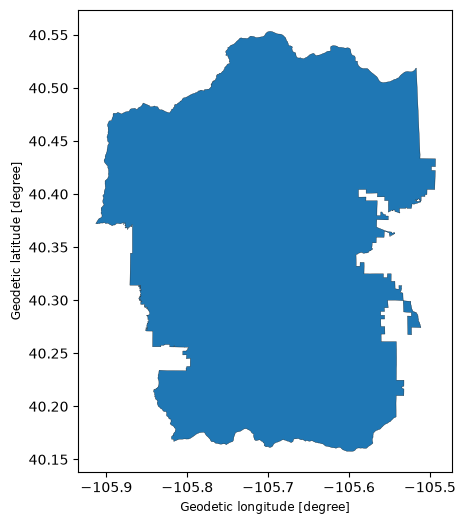

In [17]:
### plot it
romo_gdf.plot(figsize = (10,6), edgecolor = "black", linewidth = 0.2)
plt.show()

## Exploring the AppEEARS API for NASA Earthdata access

Before you get started with the data download, you will need a free [NASA Earthdata account](https://urs.earthdata.nasa.gov/home) if you don’t have one already.

You will download MODIS NDVI data for the study period. MODIS is a multispectral instrument that measures red and NIR data (and so can be used for NDVI). There are two MODIS sensors on two different platforms: satellites Terra and Aqua.

You can learn more about MODIS datasets and the science they support [here](https://modis.gsfc.nasa.gov/).

Since we’re asking for a special download that only covers our study area, we can’t just find a link to the data. Instead, we have to negotiate with the data server. We’re doing this using the
[APPEEARS](https://appeears.earthdatacloud.nasa.gov/api/) API (Application Programming Interface). The API makes it possible for you to request data using code. You can use code from the `earthpy` library to handle the API request.

Often when we want to do something more complex in coding, we find an example and modify it. This download code is already almost a working example. Your task will be to:   

- Replace the start and end dates in the task parameters. Download data from July, when greenery is at its peak in the Northern Hemisphere.  
- Replace the year range. You should get two 3 year periods so you can see the change.  
- Replace `gdf` with the name of your site geodataframe.  
- Enter your NASA Earthdata username and password when prompted at the top of your screen.


**Note:** It can take some time for Appeears to process your request - anything from a few minutes to a few hours depending on how busy they are. You can check your progress by:

1. Going to the [Appeears webpage](https://appeears.earthdatacloud.nasa.gov/)  
2. Clicking the `Explore` tab  
3. Logging in with your Earthdata account

In [18]:
### make a home for the data
project = earthpy.project.Project(
    dirname = 'romo_ndvi')
project.project_dir

PosixPath('/Users/clairewadler/Library/Application Support/earth-analytics/romo_ndvi')

In [ ]:
### make descriptive download key for the data you'll download
download_key = "RMNP NDVI"

### initialize AppeearsDownloader for MODIS NDVI data
ndvi_downloader = eaapp.AppeearsDownloader(

    ### add download key
    download_key = download_key,

    ### define folder where data will download to
    project = project,

    ### specify remote sensing product
    product = 'MOD13Q1.061',

    ### and specific layer
    layer = '_250m_16_days_NDVI',

    ### start date (change this to July)
    start_date = "07-01",

    ### end data (change this to July as well)
    end_date = "07-31",

    recurring = True,

    ### set year range
    year_range = [2021, 2021],

    ### set polygon for area of interest
    polygon = romo_gdf
)

### download the prepared data (can be slow)
ndvi_downloader.download_files(cache=True)

You can now pick up the data wrangling process from 03-vegetation-wrangle.ipynb starting at Step 3A.